In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv("../data/Diabetes_Health_Indicators.csv")
print(df.shape)
print("Missing values:", df.isna().sum().sum())
df.head()

(253680, 22)
Missing values: 0


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4,0


In [3]:
print(df["Diabetes_binary"].value_counts())
print(df["Diabetes_binary"].value_counts(normalize=True).round(3))

Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64
Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


In [4]:
print(df["BMI"].quantile([0, 0.001, 0.5, 0.999, 1]))
print(df["MentHlth"].value_counts().head(4))
print(df["PhysHlth"].value_counts().head(4))

0.000    12.0
0.001    16.0
0.500    27.0
0.999    81.0
1.000    98.0
Name: BMI, dtype: float64
MentHlth
0     175680
2      13054
30     12088
5       9030
Name: count, dtype: int64
PhysHlth
0     160052
30     19400
2      14764
1      11388
Name: count, dtype: int64


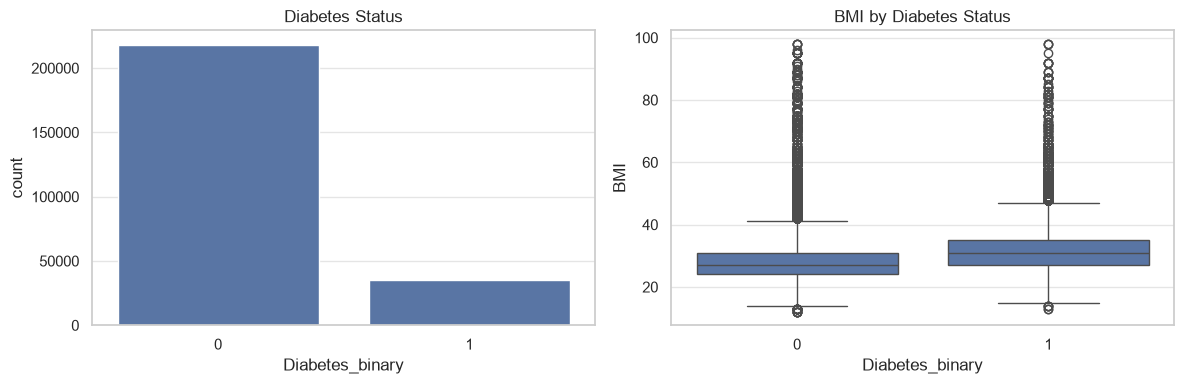

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Diabetes_binary", ax=axes[0])
axes[0].set_title("Diabetes Status")
sns.boxplot(data=df, x="Diabetes_binary", y="BMI", ax=axes[1])
axes[1].set_title("BMI by Diabetes Status")
plt.tight_layout()
plt.show()

In [6]:
df["Age_BMI"] = df["Age"] * df["BMI"]

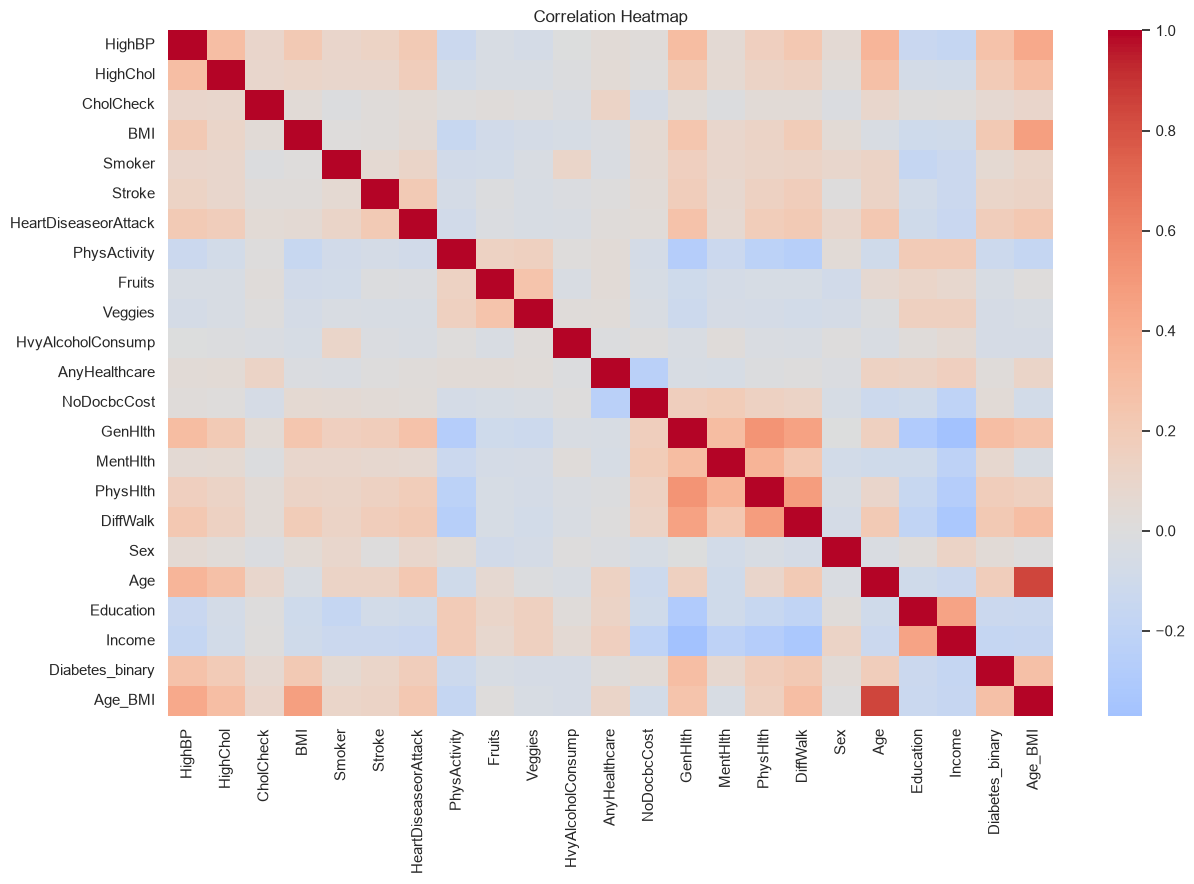

In [7]:
plt.figure(figsize=(13, 9))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [8]:
binary_features = [
    "HighBP",
    "HighChol",
    "CholCheck",
    "Smoker",
    "Stroke",
    "HeartDiseaseorAttack",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "DiffWalk",
    "Sex"
]
ordinal_features = [
    "GenHlth",
    "Age",
    "Education",
    "Income"
]
numerical_features = [
    "BMI",
    "MentHlth",
    "PhysHlth",
    "Age_BMI"
]

In [9]:
rows = []
for col in binary_features:
    rate_yes = df[df[col] == 1]["Diabetes_binary"].mean()
    rate_no = df[df[col] == 0]["Diabetes_binary"].mean()
    rows.append({"feature": col, "share with 1": df[col].mean(), "rate if 1": rate_yes,
                 "rate if 0": rate_no, "risk ratio": rate_yes / rate_no})

risk_table = pd.DataFrame(rows).sort_values("risk ratio", ascending=False)
risk_table.round(3)

,feature,share with 1,rate if 1,rate if 0,risk ratio
2,CholCheck,0.963,0.144,0.025,5.649
0,HighBP,0.429,0.244,0.060,4.051
12,DiffWalk,0.168,0.307,0.105,2.919
5,HeartDiseaseorAttack,0.094,0.330,0.120,2.758
1,HighChol,0.424,0.220,0.080,2.758
4,Stroke,0.041,0.318,0.132,2.409
3,Smoker,0.443,0.163,0.121,1.352
11,NoDocbcCost,0.084,0.175,0.136,1.288
10,AnyHealthcare,0.951,0.141,0.115,1.228
13,Sex,0.440,0.152,0.130,1.169


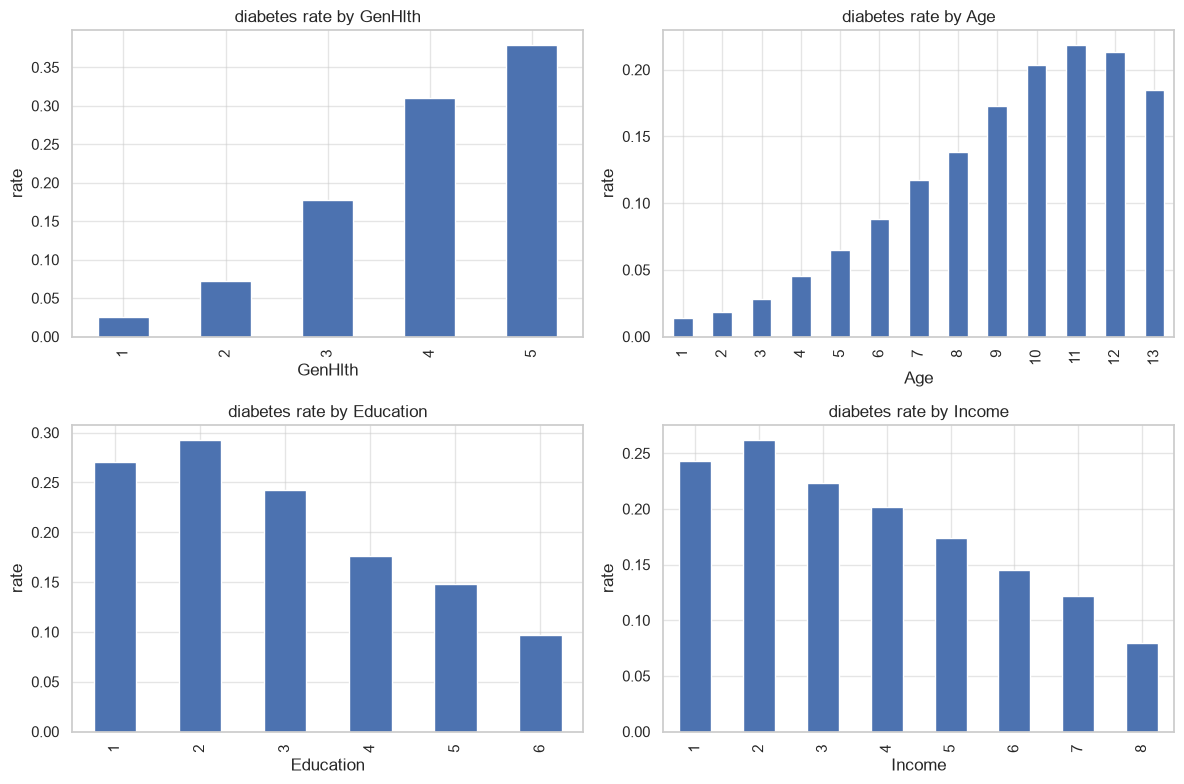

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ordinal_features):
    df.groupby(col)["Diabetes_binary"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"diabetes rate by {col}")
    ax.set_ylabel("rate")
plt.tight_layout()
plt.show()

In [11]:
X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (253680, 22)
y shape: (253680,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

print(f"\nTraining target distribution:\n{y_train.value_counts(normalize=True)}")
print(f"\nTesting target distribution:\n{y_test.value_counts(normalize=True)}")

X_train shape: (202944, 22)
X_test shape:  (50736, 22)

Training target distribution:
Diabetes_binary
0    0.860666
1    0.139334
Name: proportion, dtype: float64

Testing target distribution:
Diabetes_binary
0    0.860671
1    0.139329
Name: proportion, dtype: float64


In [13]:
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('ord', StandardScaler(), ordinal_features),
        ('bin', 'passthrough', binary_features)
    ]
)

In [14]:
lr_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=1,
        random_state=42
    ))
])

gb_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", GradientBoostingClassifier(
        n_estimators=250,
        learning_rate=0.15,
        max_depth=3,
        random_state=42
    ))
])


In [15]:
models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline,
    "Gradient Boosting": gb_pipeline
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} fitted.")


Logistic Regression fitted.
Random Forest fitted.
Gradient Boosting fitted.


In [16]:
param_grids = {
    "Logistic Regression": {
        "model__C": [1, 10]
    },
    "Random Forest": {
        "model__n_estimators": [200, 300],
        "model__max_depth": [12, None],
        "model__min_samples_leaf": [1, 2]
    },
    "Gradient Boosting": {
        "model__n_estimators": [200, 250],
        "model__learning_rate": [0.1, 0.15],
        "model__max_depth": [2, 3]
    }
}

for name, pipeline in models.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="f1",
        n_jobs=-1,
        refit=False
    )
    search.fit(X_train, y_train)
    print(name, search.best_params_, search.best_score_)

Logistic Regression {'model__C': 1} 0.25283183706250584
Random Forest {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200} 0.2414630865130008
Gradient Boosting {'model__learning_rate': 0.15, 'model__max_depth': 3, 'model__n_estimators': 250} 0.27251138799981306


In [16]:
best_thresholds = {}
roc_results = {}

for name, model in models.items():
    y_prob = cross_val_predict(
        model,
        X_train,
        y_train,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    fpr, tpr, roc_thresholds = roc_curve(y_train, y_prob)
    auc = roc_auc_score(y_train, y_prob)

    roc_results[name] = {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": roc_thresholds,
        "auc": auc
    }

    candidates = np.linspace(0, 1, 201)
    scores = [f1_score(y_train, y_prob >= t) for t in candidates]

    best = np.argmax(scores)
    best_thresholds[name] = candidates[best]

    print(f"{name}: Threshold={candidates[best]:.4f}, "
          f"CV F1={scores[best]:.4f}, ROC-AUC={auc:.4f}")

Logistic Regression: Threshold=0.2100, CV F1=0.4635, ROC-AUC=0.8244
Random Forest: Threshold=0.2500, CV F1=0.4599, ROC-AUC=0.8181
Gradient Boosting: Threshold=0.2300, CV F1=0.4715, ROC-AUC=0.8308


In [18]:
final_results = {}
summary = []

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    threshold = best_thresholds[name]
    auc = roc_auc_score(y_test, y_prob)

    predictions = {
        "Default (0.5)": (y_prob >= 0.5).astype(int),
        "F1-tuned": (y_prob >= threshold).astype(int)
    }

    final_results[name] = {
        "probability": y_prob,
        "predictions": predictions
    }

    for label, pred in predictions.items():
        report = classification_report(
            y_test,
            pred,
            output_dict=True,
            zero_division=0
        )

        summary.append({
            "Model": name,
            "Threshold": label,
            "Accuracy": report["accuracy"],
            "Precision": report["1"]["precision"],
            "Recall": report["1"]["recall"],
            "F1": report["1"]["f1-score"],
            "ROC-AUC": auc
        })

    print(f"\n{name} — F1-tuned threshold: {threshold:.4f}")
    print(classification_report(
        y_test, predictions["F1-tuned"],
        target_names=["No Diabetes", "Diabetes"],
        zero_division=0
    ))

display(pd.DataFrame(summary).round(4))


Logistic Regression — F1-tuned threshold: 0.2100
              precision    recall  f1-score   support

 No Diabetes       0.93      0.83      0.88     43667
    Diabetes       0.37      0.61      0.46      7069

    accuracy                           0.80     50736
   macro avg       0.65      0.72      0.67     50736
weighted avg       0.85      0.80      0.82     50736


Random Forest — F1-tuned threshold: 0.2500
              precision    recall  f1-score   support

 No Diabetes       0.93      0.84      0.88     43667
    Diabetes       0.37      0.59      0.45      7069

    accuracy                           0.80     50736
   macro avg       0.65      0.71      0.67     50736
weighted avg       0.85      0.80      0.82     50736


Gradient Boosting — F1-tuned threshold: 0.2300
              precision    recall  f1-score   support

 No Diabetes       0.93      0.84      0.88     43667
    Diabetes       0.38      0.62      0.47      7069

    accuracy                           0

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,Default (0.5),0.8622,0.5178,0.1647,0.2499,0.8206
1,Logistic Regression,F1-tuned,0.8002,0.3686,0.6083,0.4590,0.8206
2,Random Forest,Default (0.5),0.8652,0.5572,0.1599,0.2484,0.8136
3,Random Forest,F1-tuned,0.8040,0.3713,0.5869,0.4549,0.8136
4,Gradient Boosting,Default (0.5),0.8651,0.5509,0.1723,0.2625,0.8270
5,Gradient Boosting,F1-tuned,0.8059,0.3791,0.6161,0.4694,0.8270


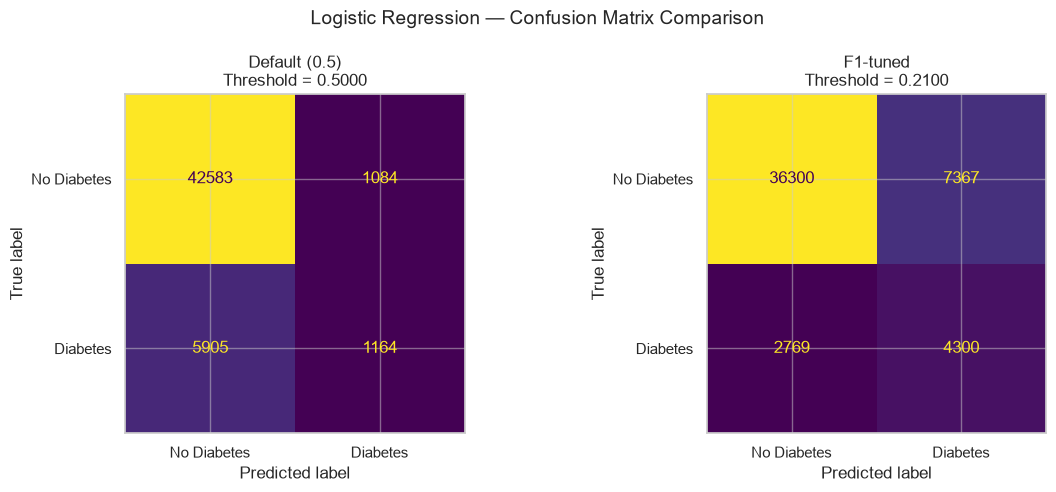

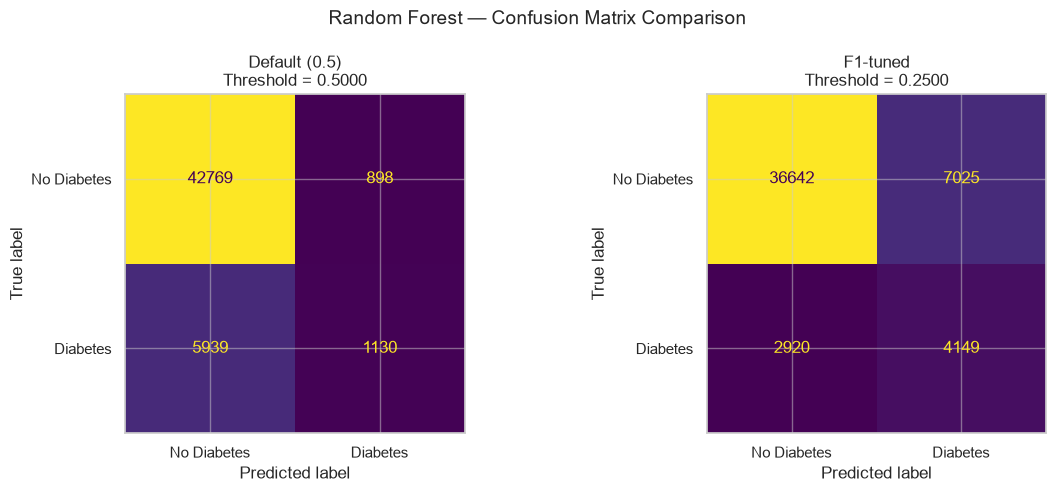

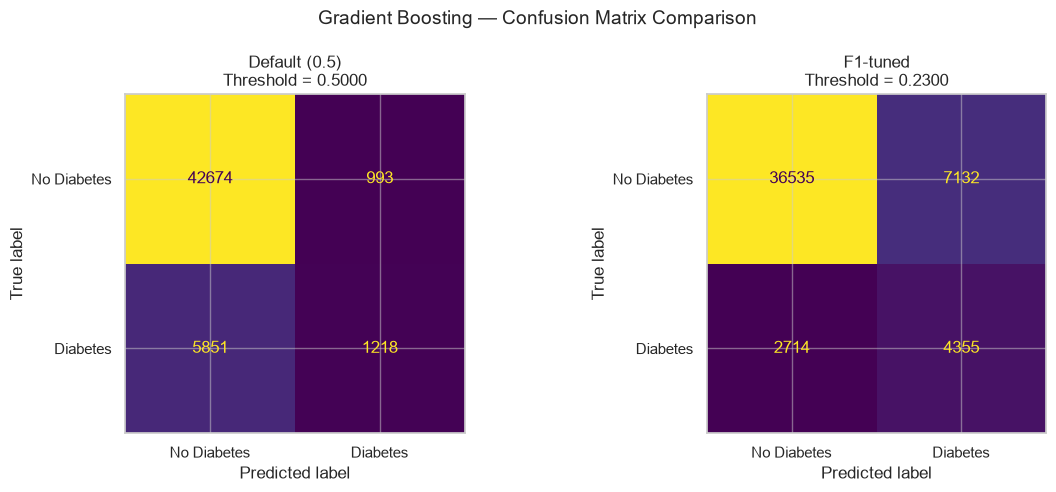

In [19]:
for name, result in final_results.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, (label, y_pred) in zip(axes, result["predictions"].items()):
        threshold = (
            0.5 if label == "Default (0.5)"
            else best_thresholds[name]
        )
        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=[0, 1]
        )
        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["No Diabetes", "Diabetes"]
        ).plot(
            ax=ax,
            values_format="d",
            colorbar=False
        )
        ax.set_title(
            f"{label}\nThreshold = {threshold:.4f}"
        )

    fig.suptitle(f"{name} — Confusion Matrix Comparison", fontsize=14)
    plt.tight_layout()
    plt.show()

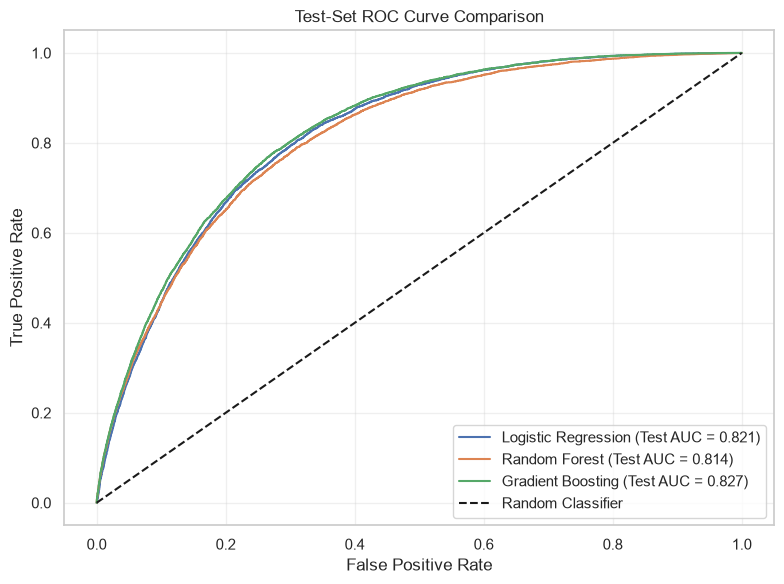

In [20]:
plt.figure(figsize=(8, 6))

for name, result in final_results.items():
    fpr, tpr, _ = roc_curve(y_test, result["probability"])
    auc = roc_auc_score(y_test, result["probability"])

    plt.plot(fpr, tpr, label=f'{name} (Test AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test-Set ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
artifact = {
    "model": gb_pipeline,
    "threshold": 0.23
}

joblib.dump(artifact, "../models/diabetes_model.joblib")

print("Model saved successfully!")

Model saved successfully!


In [22]:
artifact = joblib.load("../models/diabetes_model.joblib")

loaded_model = artifact["model"]
threshold = artifact["threshold"]

print("Model loaded successfully!")
print("Threshold:", threshold)

Model loaded successfully!
Threshold: 0.23


In [23]:
original_predictions = gb_pipeline.predict_proba(X_test)[:, 1]

loaded_predictions = loaded_model.predict_proba(X_test)[:, 1]

print("Predictions match:",
      np.allclose(original_predictions, loaded_predictions))

Predictions match: True
